In [ ]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist # Changed from mnist to fashion_mnist
from tensorflow.keras.utils import to_categorical

# Load the Fashion MNIST dataset
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Preprocess the data
# Normalize pixel values to be between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape data for LSTM: (samples, time_steps, features)
# For Fashion MNIST, each image is 28x28. We treat each row as a time step
# with 28 features.
image_rows = 28
image_cols = 28
x_train = x_train.reshape(-1, image_rows, image_cols)
x_test = x_test.reshape(-1, image_rows, image_cols)

# One-hot encode the labels
num_classes = 10
y_train = to_categorical(y_train, num_classes)
y_test = to_categorical(y_test, num_classes)

print(f"x_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"x_test shape: {x_test.shape}")
print(f"y_test shape: {y_test.shape}")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train shape: (60000, 28, 28)
y_train shape: (60000, 10)
x_test shape: (10000, 28, 28)
y_test shape: (10000, 10)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import confusion_matrix, f1_score, classification_report
import numpy as np

# Assuming image_rows, image_cols, num_classes, x_train, y_train, x_test, y_test
# are already defined from the previous data preprocessing step.

# Define the LSTM model architecture
model = Sequential()
model.add(LSTM(128, input_shape=(image_rows, image_cols), return_sequences=True)) # Increased units
model.add(Dropout(0.2))
model.add(LSTM(64))
model.add(Dropout(0.2))
model.add(Dense(num_classes, activation='softmax'))

# Compile the model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

print("Model Summary:")
model.summary()

# Train the LSTM Model
batch_size = 128
epochs = 10

print(f"\nTraining the model for {epochs} epochs...")
history = model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.2, verbose=1)

print("\nModel training complete. Evaluating performance...")

# Evaluate the model on the test data
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"\nTest Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

# Make predictions on the test set
y_pred_probs = model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

# Calculate Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Calculate Classification Report (includes Precision, Recall, F1-score)
class_report = classification_report(y_true, y_pred)
print("\nClassification Report:")
print(class_report)

# You can also get F1-score specifically if needed
f1 = f1_score(y_true, y_pred, average='weighted')
print(f"\nWeighted F1-score: {f1:.4f}")

Model Summary:


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 28, 128)        │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,442 (509.54 KB)

 Trainable params: 130,442 (509.54 KB)

 Non-trainable params: 0 (0.00 B)


Training the model for 10 epochs...
Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 47s 117ms/step - accuracy: 0.7267 - loss: 0.7347 - val_accuracy: 0.8070 - val_loss: 0.5151
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 83s 119ms/step - accuracy: 0.8231 - loss: 0.4879 - val_accuracy: 0.8281 - val_loss: 0.4670
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 82s 119ms/step - accuracy: 0.8413 - loss: 0.4351 - val_accuracy: 0.8540 - val_loss: 0.4023
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 43s 115ms/step - accuracy: 0.8537 - loss: 0.4022 - val_accuracy: 0.8528 - val_loss: 0.3961
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 44s 118ms/step - accuracy: 0.8628 - loss: 0.3733 - val_accuracy: 0.8607 - val_loss: 0.3844
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 81s 116ms/step - accuracy: 0.8692 - loss: 0.3532 - val_accuracy: 0.8697 - val_loss: 0.3504
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 45s 119ms/step - accuracy: 0.8745 - loss: 0.3406 - val_accuracy: 0.8722 - val_loss: 0.3428
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 44s 11

<>:26: SyntaxWarning: invalid escape sequence '\s'
<>:26: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1235/2941363179.py:26: SyntaxWarning: invalid escape sequence '\s'
  df_report = pd.read_csv(report_data, sep='\s{2,}', engine='python', index_col=0)



Generating plots for Precision, Recall, and F1-score with class names...


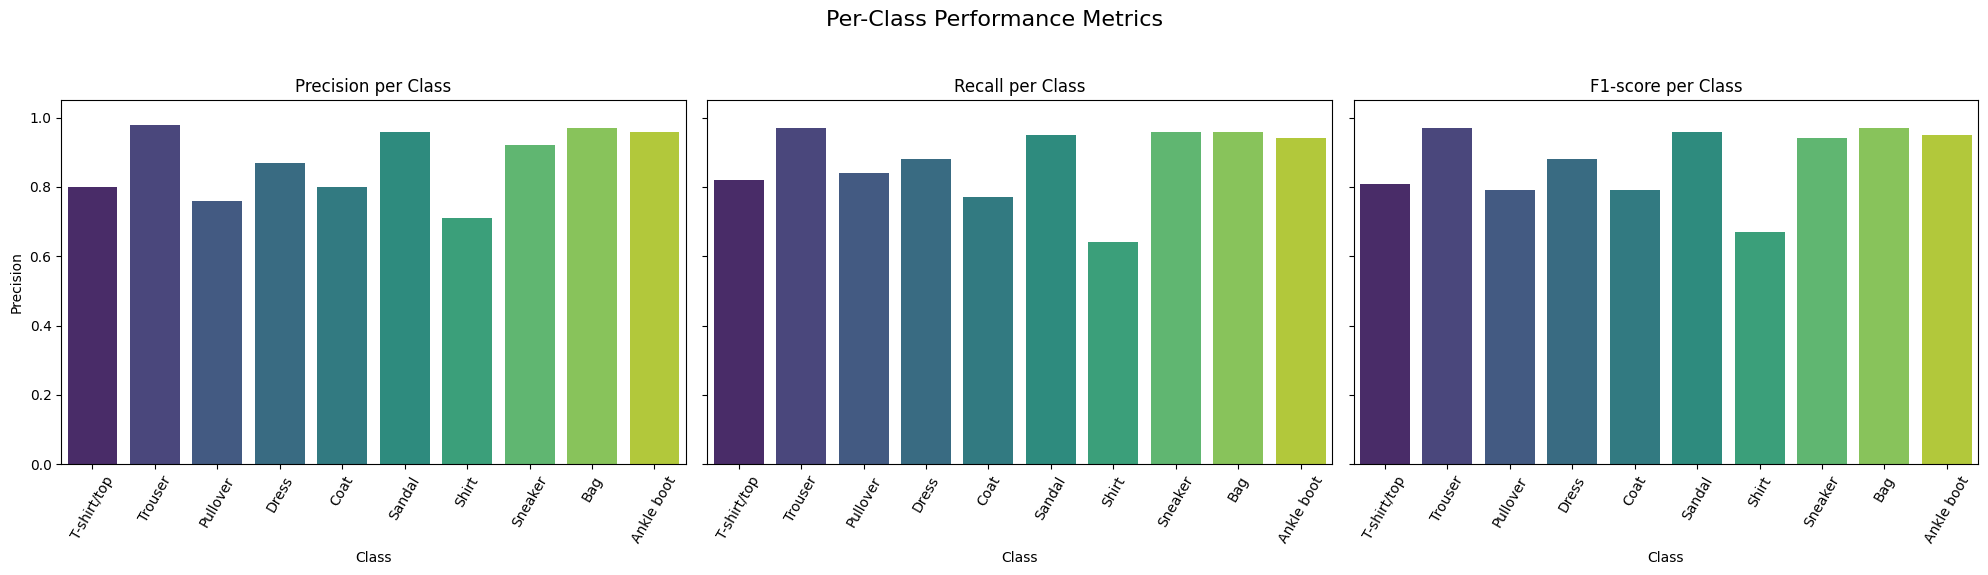


Generating plot for Confusion Matrix with class names...


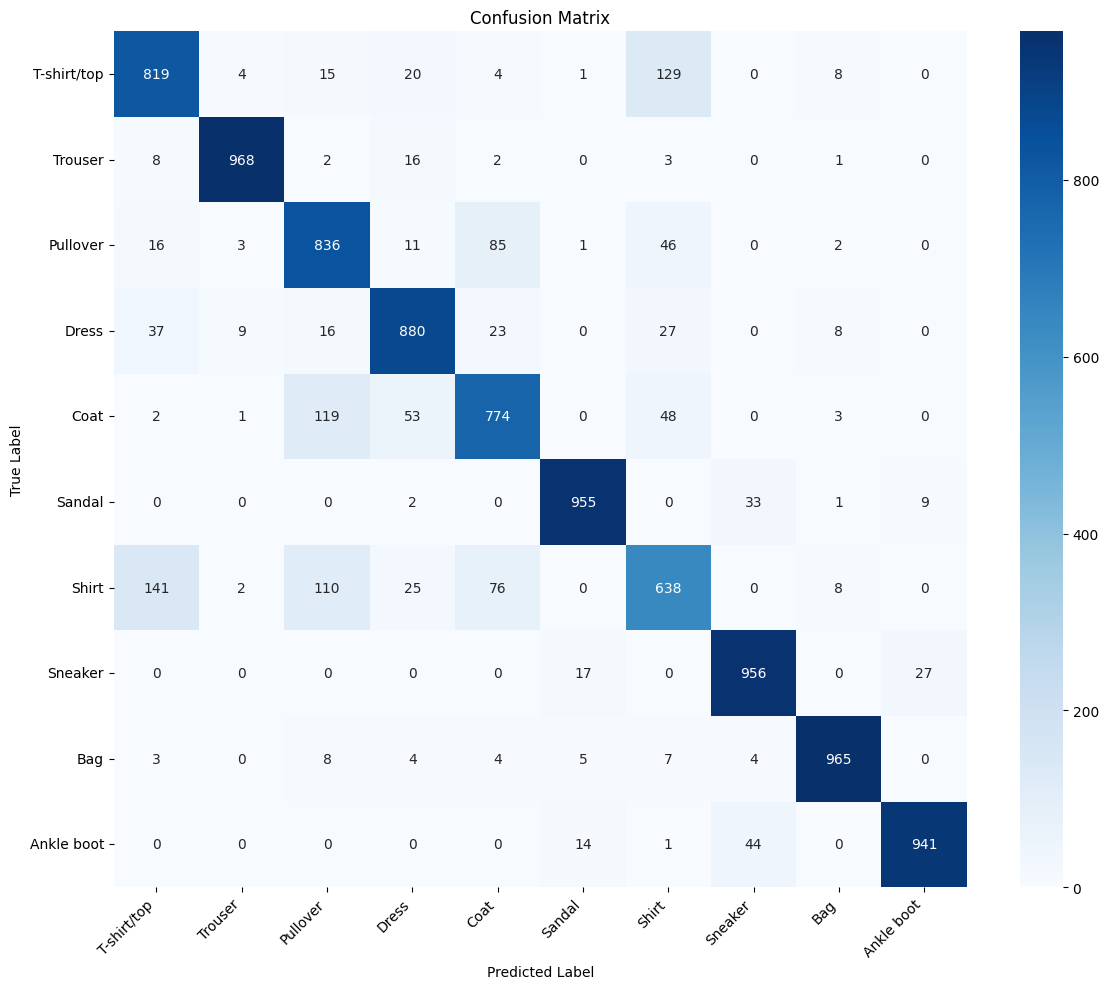

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from io import StringIO

# Define Fashion MNIST class names
fashion_mnist_labels = {
    0: 'T-shirt/top',
    1: 'Trouser',
    2: 'Pullover',
    3: 'Dress',
    4: 'Coat',
    5: 'Sandal',
    6: 'Shirt',
    7: 'Sneaker',
    8: 'Bag',
    9: 'Ankle boot'
}
class_names = [fashion_mnist_labels[i] for i in range(num_classes)]

# --- Plotting Classification Report Metrics (Precision, Recall, F1-score) ---
print("\nGenerating plots for Precision, Recall, and F1-score with class names...")

# Parse the classification report string into a DataFrame
report_data = StringIO(class_report)
df_report = pd.read_csv(report_data, sep='\s{2,}', engine='python', index_col=0)

# Drop the 'accuracy', 'macro avg', and 'weighted avg' rows if they exist
df_metrics = df_report.drop(columns=['support'], errors='ignore')
df_metrics = df_metrics.drop(['accuracy', 'macro avg', 'weighted avg'], errors='ignore')

# Map the numeric index to class names for plotting
df_metrics.index = class_names

metrics = ['precision', 'recall', 'f1-score']
n_classes = len(df_metrics)

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 6), sharey=True) # Increased figure width
fig.suptitle('Per-Class Performance Metrics', fontsize=16)

colors = sns.color_palette('viridis', n_colors=n_classes)

for i, metric in enumerate(metrics):
    # Pass x as class names and set hue for correct palette usage with future seaborn versions
    sns.barplot(x=df_metrics.index, y=df_metrics[metric], ax=axes[i], palette=colors, hue=df_metrics.index, legend=False)
    axes[i].set_title(f'{metric.capitalize()} per Class')
    axes[i].set_xlabel('Class')
    axes[i].set_ylabel(metric.capitalize())
    axes[i].set_ylim(0, 1.05)
    axes[i].tick_params(axis='x', rotation=60) # Increased rotation for longer labels

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


# --- Plotting Confusion Matrix ---
print("\nGenerating plot for Confusion Matrix with class names...")

plt.figure(figsize=(12, 10)) # Increased figure size
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for readability
plt.yticks(rotation=0) # Keep y-axis labels horizontal
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical

# Load the Fashion MNIST dataset
(x_train_cnn_fashion, y_train_cnn_fashion), (x_test_cnn_fashion, y_test_cnn_fashion) = fashion_mnist.load_data()

# Preprocess the data for CNN
# Normalize pixel values to be between 0 and 1
x_train_cnn_fashion = x_train_cnn_fashion.astype('float32') / 255.0
x_test_cnn_fashion = x_test_cnn_fashion.astype('float32') / 255.0

# Reshape data for CNN: (samples, height, width, channels)
# Fashion MNIST images are 28x28, and they are grayscale, so add a channel dimension of 1.
image_rows_fashion = 28
image_cols_fashion = 28
x_train_cnn_fashion = x_train_cnn_fashion.reshape(x_train_cnn_fashion.shape[0], image_rows_fashion, image_cols_fashion, 1)
x_test_cnn_fashion = x_test_cnn_fashion.reshape(x_test_cnn_fashion.shape[0], image_rows_fashion, image_cols_fashion, 1)

# One-hot encode the labels
num_classes_fashion = 10
y_train_cnn_fashion = to_categorical(y_train_cnn_fashion, num_classes_fashion)
y_test_cnn_fashion = to_categorical(y_test_cnn_fashion, num_classes_fashion)

print(f"x_train_cnn_fashion shape: {x_train_cnn_fashion.shape}")
print(f"y_train_cnn_fashion shape: {y_train_cnn_fashion.shape}")
print(f"x_test_cnn_fashion shape: {x_test_cnn_fashion.shape}")
print(f"y_test_cnn_fashion shape: {y_test_cnn_fashion.shape}")

x_train_cnn_fashion shape: (60000, 28, 28, 1)
y_train_cnn_fashion shape: (60000, 10)
x_test_cnn_fashion shape: (10000, 28, 28, 1)
y_test_cnn_fashion shape: (10000, 10)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Define the CNN model architecture
cnn_model_fashion = Sequential()

# Convolutional Layer 1
cnn_model_fashion.add(Conv2D(32, (3, 3), activation='relu', input_shape=(image_rows_fashion, image_cols_fashion, 1)))
cnn_model_fashion.add(MaxPooling2D((2, 2)))

# Convolutional Layer 2
cnn_model_fashion.add(Conv2D(64, (3, 3), activation='relu'))
cnn_model_fashion.add(MaxPooling2D((2, 2)))

# Convolutional Layer 3 (optional, can add more)
cnn_model_fashion.add(Conv2D(128, (3, 3), activation='relu'))
cnn_model_fashion.add(MaxPooling2D((2, 2)))

# Flatten the output for the Dense layers
cnn_model_fashion.add(Flatten())

# Dense Layers
cnn_model_fashion.add(Dense(128, activation='relu'))
cnn_model_fashion.add(Dropout(0.5)) # Dropout for regularization
cnn_model_fashion.add(Dense(num_classes_fashion, activation='softmax')) # Output layer

# Compile the model
cnn_model_fashion.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("CNN Model Summary:")
cnn_model_fashion.summary()

CNN Model Summary:


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,474 (431.54 KB)

 Trainable params: 110,474 (431.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from sklearn.metrics import confusion_matrix, f1_score, classification_report
import numpy as np

# Train the CNN Model
batch_size_cnn_fashion = 128
epochs_cnn_fashion = 10

print(f"\nTraining the CNN model for {epochs_cnn_fashion} epochs...")
history_cnn_fashion = cnn_model_fashion.fit(x_train_cnn_fashion, y_train_cnn_fashion,
                                            batch_size=batch_size_cnn_fashion,
                                            epochs=epochs_cnn_fashion,
                                            validation_split=0.2,
                                            verbose=1)

print("\nCNN Model training complete. Evaluating performance...")

# Evaluate the model on the test data
loss_cnn_fashion, accuracy_cnn_fashion = cnn_model_fashion.evaluate(x_test_cnn_fashion, y_test_cnn_fashion, verbose=0)
print(f"\nTest Loss (CNN): {loss_cnn_fashion:.4f}")
print(f"Test Accuracy (CNN): {accuracy_cnn_fashion:.4f}")

# Make predictions on the test set
y_pred_probs_cnn_fashion = cnn_model_fashion.predict(x_test_cnn_fashion)
y_pred_cnn_fashion = np.argmax(y_pred_probs_cnn_fashion, axis=1)
y_true_cnn_fashion = np.argmax(y_test_cnn_fashion, axis=1)

# Calculate Confusion Matrix
cm_cnn_fashion = confusion_matrix(y_true_cnn_fashion, y_pred_cnn_fashion)
print("\nConfusion Matrix (CNN):")
print(cm_cnn_fashion)

# Calculate Classification Report (includes Precision, Recall, F1-score)
class_report_cnn_fashion = classification_report(y_true_cnn_fashion, y_pred_cnn_fashion)
print("\nClassification Report (CNN):")
print(class_report_cnn_fashion)

# You can also get F1-score specifically if needed
f1_cnn_fashion = f1_score(y_true_cnn_fashion, y_pred_cnn_fashion, average='weighted')
print(f"\nWeighted F1-score (CNN): {f1_cnn_fashion:.4f}")


Training the CNN model for 10 epochs...
Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 103ms/step - accuracy: 0.7039 - loss: 0.8148 - val_accuracy: 0.8124 - val_loss: 0.5146
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 107ms/step - accuracy: 0.8151 - loss: 0.5142 - val_accuracy: 0.8394 - val_loss: 0.4534
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 39s 103ms/step - accuracy: 0.8415 - loss: 0.4397 - val_accuracy: 0.8588 - val_loss: 0.3828
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 38s 102ms/step - accuracy: 0.8562 - loss: 0.4007 - val_accuracy: 0.8683 - val_loss: 0.3588
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 102ms/step - accuracy: 0.8669 - loss: 0.3695 - val_accuracy: 0.8708 - val_loss: 0.3526
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 101ms/step - accuracy: 0.8770 - loss: 0.3403 - val_accuracy: 0.8738 - val_loss: 0.3405
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 38s 102ms/step - accuracy: 0.8842 - loss: 0.3219 - val_accuracy: 0.8755 - val_loss: 0.3299
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 38

<>:26: SyntaxWarning: invalid escape sequence '\s'
<>:26: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1235/30687975.py:26: SyntaxWarning: invalid escape sequence '\s'
  df_report_cnn_fashion = pd.read_csv(report_data_cnn_fashion, sep='\s{2,}', engine='python', index_col=0)



Generating plots for Precision, Recall, and F1-score for CNN with class names...


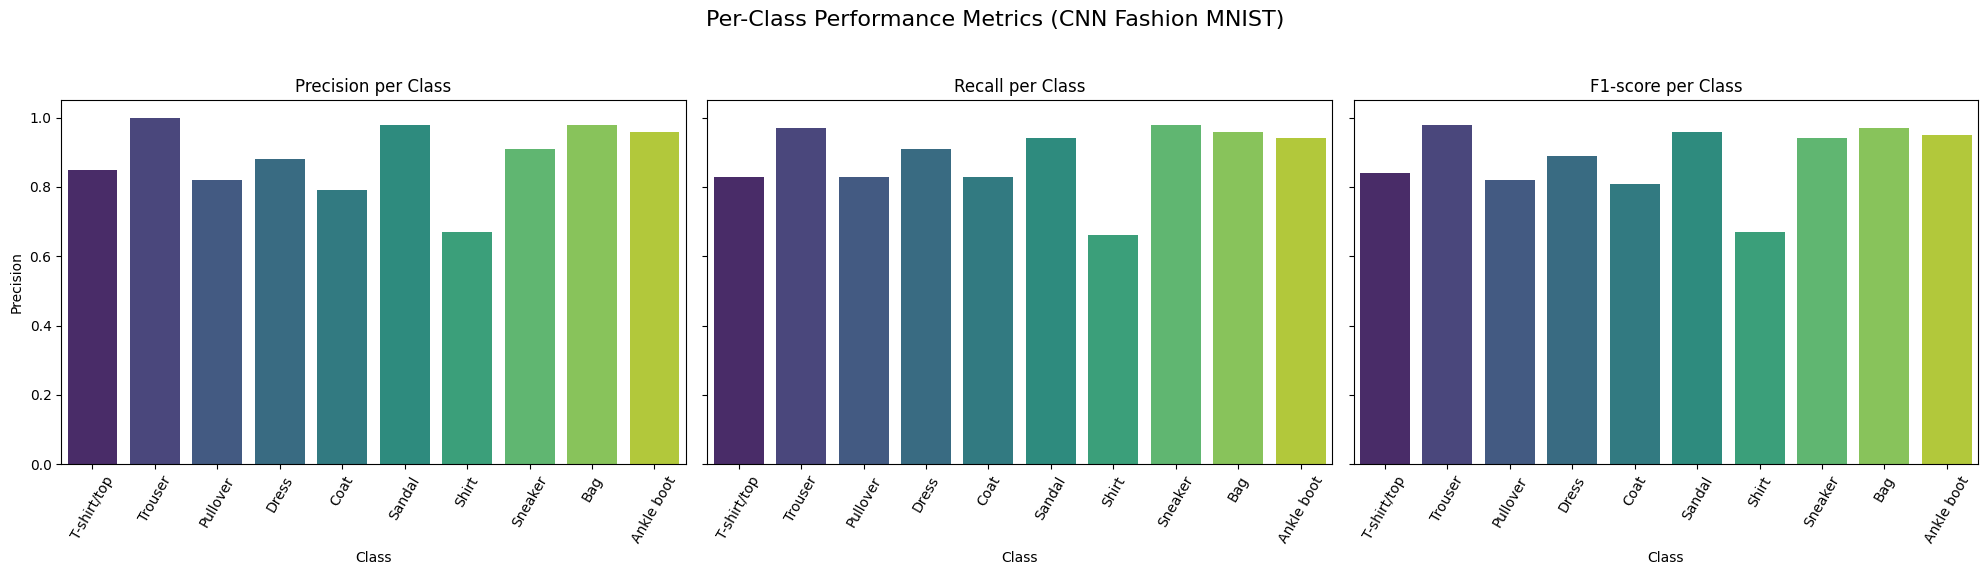


Generating plot for Confusion Matrix (CNN) with class names...


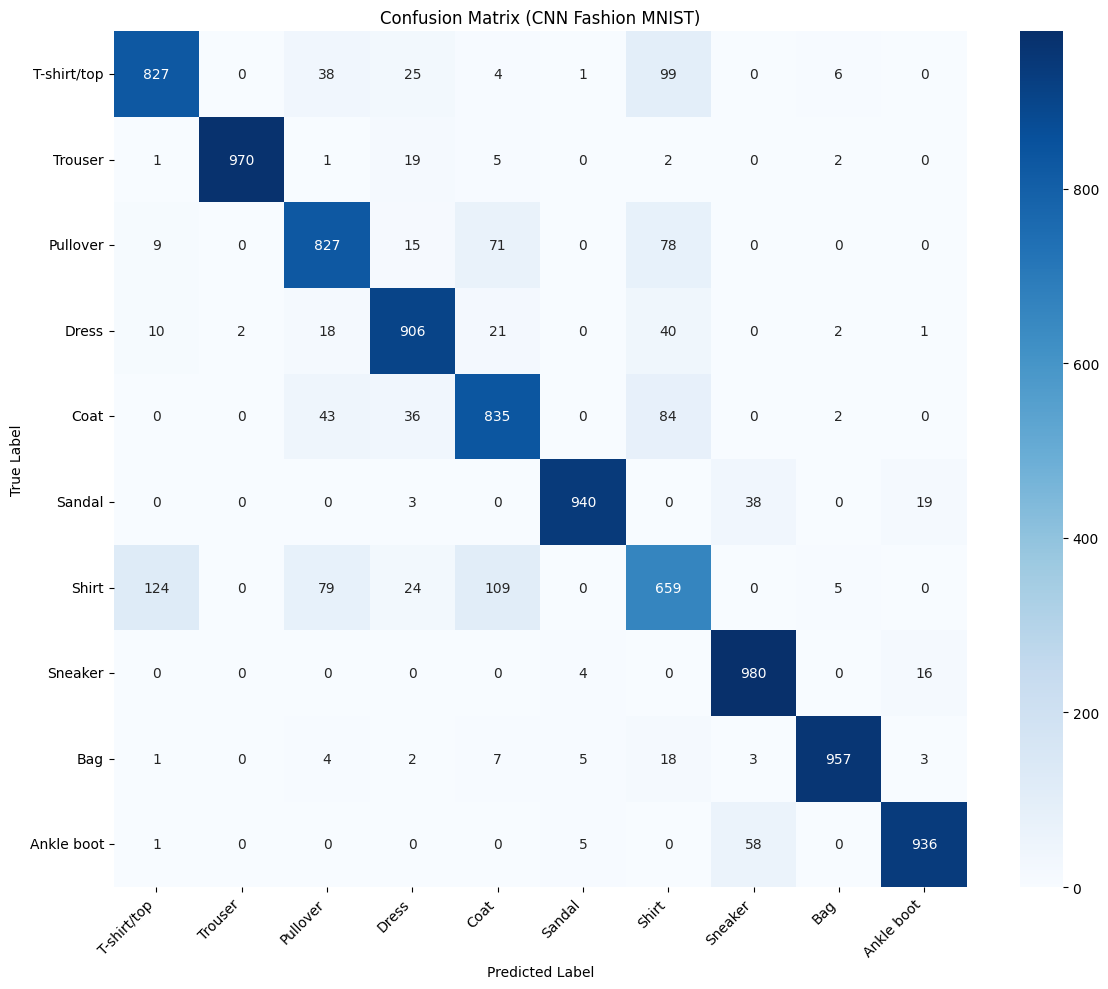

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from io import StringIO

# Define Fashion MNIST class names (already defined in previous cells, but good to include for self-containment)
fashion_mnist_labels = {
    0: 'T-shirt/top',
    1: 'Trouser',
    2: 'Pullover',
    3: 'Dress',
    4: 'Coat',
    5: 'Sandal',
    6: 'Shirt',
    7: 'Sneaker',
    8: 'Bag',
    9: 'Ankle boot'
}
class_names_cnn_fashion = [fashion_mnist_labels[i] for i in range(num_classes_fashion)]

# --- Plotting Classification Report Metrics (Precision, Recall, F1-score) for CNN ---
print("\nGenerating plots for Precision, Recall, and F1-score for CNN with class names...")

# Parse the classification report string into a DataFrame for CNN
report_data_cnn_fashion = StringIO(class_report_cnn_fashion)
df_report_cnn_fashion = pd.read_csv(report_data_cnn_fashion, sep='\s{2,}', engine='python', index_col=0)

# Drop the 'accuracy', 'macro avg', and 'weighted avg' rows if they exist
df_metrics_cnn_fashion = df_report_cnn_fashion.drop(columns=['support'], errors='ignore')
df_metrics_cnn_fashion = df_metrics_cnn_fashion.drop(['accuracy', 'macro avg', 'weighted avg'], errors='ignore')

# Map the numeric index to class names for plotting
df_metrics_cnn_fashion.index = class_names_cnn_fashion

metrics_cnn_fashion = ['precision', 'recall', 'f1-score']
n_classes_cnn_fashion = len(df_metrics_cnn_fashion)

fig_cnn_fashion, axes_cnn_fashion = plt.subplots(nrows=1, ncols=3, figsize=(20, 6), sharey=True) # Increased figure width
fig_cnn_fashion.suptitle('Per-Class Performance Metrics (CNN Fashion MNIST)', fontsize=16)

colors_cnn_fashion = sns.color_palette('viridis', n_colors=n_classes_cnn_fashion)

for i, metric_cnn in enumerate(metrics_cnn_fashion):
    # Pass x as class names and set hue for correct palette usage with future seaborn versions
    sns.barplot(x=df_metrics_cnn_fashion.index, y=df_metrics_cnn_fashion[metric_cnn], ax=axes_cnn_fashion[i], palette=colors_cnn_fashion, hue=df_metrics_cnn_fashion.index, legend=False)
    axes_cnn_fashion[i].set_title(f'{metric_cnn.capitalize()} per Class')
    axes_cnn_fashion[i].set_xlabel('Class')
    axes_cnn_fashion[i].set_ylabel(metric_cnn.capitalize())
    axes_cnn_fashion[i].set_ylim(0, 1.05)
    axes_cnn_fashion[i].tick_params(axis='x', rotation=60) # Increased rotation for longer labels

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


# --- Plotting Confusion Matrix for CNN ---
print("\nGenerating plot for Confusion Matrix (CNN) with class names...")

plt.figure(figsize=(12, 10)) # Increased figure size
sns.heatmap(cm_cnn_fashion, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=class_names_cnn_fashion,
            yticklabels=class_names_cnn_fashion)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (CNN Fashion MNIST)')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for readability
plt.yticks(rotation=0) # Keep y-axis labels horizontal
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()